In [1]:
import pandas as pd
import numpy as np
import fancyimpute
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [2]:
df = pd.read_csv(r"E:\Imarticus_ Learning\Jobs - 2026\Models\data\unzipped\Life Expectancy Data.csv")
df.shape

(2938, 22)

In [3]:
df.columns = ['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure',
       'Diphtheria', ' HIV/AIDS', 'GDP', 'Population',
       'thinness  1-19 years', 'thinness 5-9 years',
       'Income composition of resources', 'Schooling']

In [4]:
df.columns

Index(['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure',
       'Diphtheria', ' HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years',
       'thinness 5-9 years', 'Income composition of resources', 'Schooling'],
      dtype='object')

In [5]:
df.value_counts('Status')

Status
Developing    2426
Developed      512
Name: count, dtype: int64

In [6]:
df = df.drop(columns = ['Country'])
encode = {
    'Developing' : 0,
    'Developed' : 1
}
df['Status'] = df['Status'].map(encode)

In [7]:
imp = fancyimpute.IterativeImputer().fit(df)

In [8]:
df_new = imp.transform(df)

In [9]:
df_new = pd.DataFrame(data= df_new, columns = df.columns)

In [10]:
x = df_new.drop(columns = 'Status')
y = df_new['Status']

In [11]:
X_train, X_test, y_train , y_test = train_test_split(x, y, test_size = 0.3, random_state = 0, stratify = y)

In [12]:
sc = StandardScaler().fit(X_train)
sc_train_array = sc.transform(X_train)
sc_train = pd.DataFrame(data = sc_train_array, columns = X_train.columns)
sc_test_array = sc.transform(X_test)
sc_test = pd.DataFrame(data = sc_test_array, columns = X_test.columns)

In [13]:
logimodel = LogisticRegression()
logimodel.fit(sc_train, y_train)

LogisticRegression()

In [14]:
logimodel.intercept_

array([-6.38019083])

In [15]:
coeff = (np.e**(logimodel.coef_)).flatten().tolist()
coeff_list = [logimodel.intercept_[0]] + coeff

print(coeff_list)

[np.float64(-6.380190825586871), 0.6501245219981139, 1.4612738655193878, 0.4236338994094686, 0.9646654276836387, 3.871436620335729, 0.9442364195657258, 1.9217767517074091, 1.086971320327328, 0.8984970114242172, 1.0155916313636153, 0.9723838813436739, 1.229287376310529, 1.0115939990416514, 0.6960872380022091, 1.1550479851144189, 0.5841932051940544, 0.29716609496123286, 1.1779237856263791, 32.80644300628594, 0.9667784195099866]


In [16]:
X_train.columns

Index(['Year', 'Life expectancy', 'Adult Mortality', 'infant deaths',
       'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI',
       'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria',
       ' HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years',
       'thinness 5-9 years', 'Income composition of resources', 'Schooling'],
      dtype='object')

In [17]:
coeff_df = pd.DataFrame( data = coeff_list, columns = ['Estimates'], index = ['Intercept','Year', 'Life expectancy', 'Adult Mortality', 'infant deaths',
       'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI',
       'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria',
       ' HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years',
       'thinness 5-9 years', 'Income composition of resources', 'Schooling'])
    

In [18]:
coeff_df.sort_values(by = 'Estimates')

,Estimates
Intercept,-6.380
thinness 1-19 years,0.297
Adult Mortality,0.424
Population,0.584
Year,0.650
HIV/AIDS,0.696
BMI,0.898
percentage expenditure,0.944
infant deaths,0.965
Schooling,0.967


In [19]:
pred_train = logimodel.predict_proba(sc_train)
pred_test = logimodel.predict_proba(sc_test)

In [112]:
pred_train.shape

(2056, 2)

In [113]:
pred_train.shape

(2056, 2)

In [22]:
out_class_train = []
for i in pred_train:
    max = i.max()
    pos = list(i).index(max)
    out_class_train.append(pos)

out_class_test = []
for i in pred_test:
    max = i.max()
    pos = list(i).index(max)
    out_class_test.append(pos)

In [23]:
conf_train = confusion_matrix(y_train, out_class_train)
conf_train

array([[1640,   58],
       [  61,  297]])

In [24]:
acc_train = conf_train.diagonal().sum()/conf_train.sum()
acc_train

np.float64(0.9421206225680934)

In [25]:
confusion_matrix(y_test, out_class_test)

array([[704,  24],
       [ 33, 121]])

In [26]:
print(classification_report(y_train, out_class_train))

              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96      1698
         1.0       0.84      0.83      0.83       358

    accuracy                           0.94      2056
   macro avg       0.90      0.90      0.90      2056
weighted avg       0.94      0.94      0.94      2056



In [27]:
print(classification_report(y_test, out_class_test))

              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96       728
         1.0       0.83      0.79      0.81       154

    accuracy                           0.94       882
   macro avg       0.89      0.88      0.89       882
weighted avg       0.93      0.94      0.93       882



In [28]:
solver = ['lbfgs', 'liblinear', 'newton-cg' , 'newton-cholesky', 'sag', 'saga']
for i in solver:
    lmodel = LogisticRegression(solver = i, n_jobs=-1, random_state=0, max_iter = 1000).fit(sc_train, y_train)
    pred_train_ = lmodel.predict(sc_train)
    pred_test_ = lmodel.predict(sc_test)
    acc_train = classification_report(y_train , pred_train_)
    acc_test = classification_report(y_test, pred_test_)
    print(f'classification_report of Train is \n{acc_train},\n classification_report of Test is \n{acc_test},\n when solver is {i}')

classification_report of Train is 
              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96      1698
         1.0       0.84      0.83      0.83       358

    accuracy                           0.94      2056
   macro avg       0.90      0.90      0.90      2056
weighted avg       0.94      0.94      0.94      2056
,
 classification_report of Test is 
              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96       728
         1.0       0.83      0.79      0.81       154

    accuracy                           0.94       882
   macro avg       0.89      0.88      0.89       882
weighted avg       0.93      0.94      0.93       882
,
 when solver is lbfgs
classification_report of Train is 
              precision    recall  f1-score   support

         0.0       0.97      0.97      0.97      1698
         1.0       0.84      0.84      0.84       358

    accuracy                           0.94      2056

E:\anaconda3\envs\ml_3.12\Lib\site-packages\sklearn\linear_model\_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 16.
  warnings.warn(


classification_report of Train is 
              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96      1698
         1.0       0.84      0.83      0.83       358

    accuracy                           0.94      2056
   macro avg       0.90      0.90      0.90      2056
weighted avg       0.94      0.94      0.94      2056
,
 classification_report of Test is 
              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96       728
         1.0       0.84      0.79      0.82       154

    accuracy                           0.94       882
   macro avg       0.90      0.88      0.89       882
weighted avg       0.94      0.94      0.94       882
,
 when solver is newton-cg
classification_report of Train is 
              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96      1698
         1.0       0.84      0.83      0.83       358

    accuracy                           0.94      

In [29]:
from pathlib import Path
import joblib

save_dir = Path(r'E:\Imarticus_ Learning\Jobs - 2026\Models\models')
joblib.dump(logimodel, save_dir / 'Logistic_regression_model.pkl')

['E:\\Imarticus_ Learning\\Jobs - 2026\\Models\\models\\Logistic_regression_model.pkl']

In [44]:
# Verifing the model performance apart from the Classification report
# Calculate cohen's kappa score to check the model has performed really well but not by random chances
from sklearn.metrics import cohen_kappa_score
cohen_kappa_score(y_train, out_class_train)

np.float64(0.7980900319208284)

In [45]:
df['Status'].value_counts()

Status
0    2426
1     512
Name: count, dtype: int64

In [68]:
# Calculate the no information Rate where NIR accuracy must be less that the Algorithm based model Accuracy
nir_df = pd.DataFrame()
nir_df['Predicted'] = out_class_train
nir_df['observed'] = y_train.values
nir_df['no_model_classes'] = 0

In [69]:
accuracy_score(nir_df['observed'] , nir_df['no_model_classes'])

0.8258754863813229

In [70]:
accuracy_score(nir_df['observed'] , nir_df['Predicted'])

0.9421206225680934

In [75]:
prob_train = pred_train[:,1]

In [76]:
# ROC curve and AUC curve is to estimate the FPR and TPR and threshold for the Decision making in the Logistic Regression

from sklearn.metrics import roc_curve , auc
fpr,tpr,thresholds = roc_curve(y_train, prob_train)


In [77]:
auc(fpr, tpr)

np.float64(0.9765119660987952)

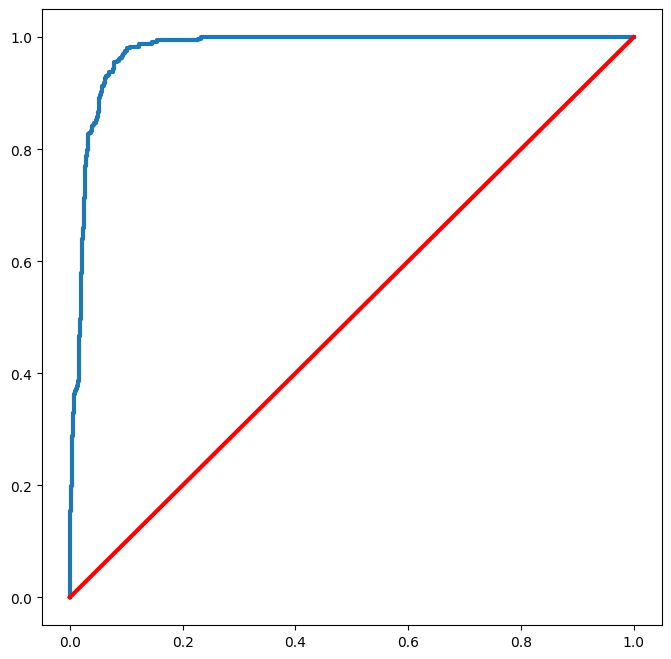

In [78]:
import matplotlib.pyplot as plt
plt.figure(figsize = (8,8))
lw = 3
plt.plot(
    fpr,
    tpr,
    lw = lw
)
plt.plot([0,1],[0,1], color = 'red', lw = 3)
plt.show()

In [80]:
import statsmodels.api as sm

In [83]:
y_train.reset_index(inplace = True, drop = True)

In [85]:
logimodel_stats = sm.Logit(
y_train,sc_train
).fit()

Optimization terminated successfully.
         Current function value: 0.492884
         Iterations 7


In [86]:
logimodel_stats.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 Status   No. Observations:                 2056
Model:                          Logit   Df Residuals:                     2036
Method:                           MLE   Df Model:                           19
Date:                Sun, 02 Aug 2026   Pseudo R-squ.:                -0.06600
Time:                        13:51:53   Log-Likelihood:                -1013.4
converged:                       True   LL-Null:                       -950.63
Covariance Type:            nonrobust   LLR p-value:                     1.000
===================================================================================================
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Year                               -0.0256      0.060     -0.430      0.667      -0.142       0.091
Life expectancy                     0.1607      0.134      1.201      0.230      -0.102       0.423
Adult Mortality                    -0.1400      0.077     -1.827      0.068      -0.290       0.010
infant deaths                      -0.2955      0.734     -0.402      0.687      -1.735       1.144
Alcohol                             0.6764      0.074      9.177      0.000       0.532       0.821
percentage expenditure              2.4976      0.243     10.271      0.000       2.021       2.974
Hepatitis B                         0.0850      0.081      1.046      0.295      -0.074       0.244
Measles                             0.0098      0.062      0.158      0.874      -0.111       0.131
BMI                                -0.2069      0.075     -2.742      0.006      -0.355      -0.059
under-five deaths                   0.3941      0.730      0.540      0.589      -1.036       1.825
Polio                              -0.0387      0.079     -0.492      0.623      -0.193       0.115
Total expenditure                   0.2264      0.064      3.534      0.000       0.101       0.352
Diphtheria                         -0.0577      0.088     -0.658      0.511      -0.230       0.114
 HIV/AIDS                           0.0054      0.071      0.076      0.940      -0.133       0.144
GDP                                -0.2723      0.160     -1.698      0.089      -0.586       0.042
Population                         -0.0830      0.082     -1.006      0.314      -0.245       0.079
thinness  1-19 years               -0.0673      0.184     -0.366      0.715      -0.428       0.293
thinness 5-9 years                 -0.0358      0.185     -0.194      0.846      -0.398       0.326
Income composition of resources     0.1261      0.102      1.242      0.214      -0.073       0.325
Schooling                           0.0942      0.120      0.788      0.431      -0.140       0.329
===================================================================================================
"""

In [107]:
ll_null = -1013.4
ll_model = -950.63
n = len(y_train)

cox_snell = 1 - np.exp((2/n) * (ll_null - ll_model))

print(cox_snell)

0.05923350077057732


In [108]:
# Maximum possible Cox & Snell R²
max_cs = 1 - np.exp((2 / n) * ll_null)
max_cs

np.float64(0.6268585338298213)

In [109]:
# Nagelkerke R²
nagelkerke = cox_snell / max_cs

print("Nagelkerke R²  :", nagelkerke)

Nagelkerke R²  : 0.094492612884581


In [110]:
"""
Suppose your confusion matrix is good,

your ROC-AUC is high,

your precision and recall are good.

Then

Nagelkerke = 0.094

is completely acceptable."""

'\nSuppose your confusion matrix is good,\n\nyour ROC-AUC is high,\n\nyour precision and recall are good.\n\nThen\n\nNagelkerke = 0.094\n\nis completely acceptable.'

In [111]:
class_label = []

for i in pred_train:
    if i > 0.5:
        class_label.append(1)
    else:
        class_label.append(0)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()